In [1]:


!cd /kaggle/working && git clone https://github.com/maudzung/SFA3D.git

Cloning into 'SFA3D'...
remote: Enumerating objects: 300, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 300 (delta 63), reused 49 (delta 49), pack-reused 208 (from 1)
Receiving objects: 100% (300/300), 45.48 MiB | 19.26 MiB/s, done.
Resolving deltas: 100% (153/153), done.


In [2]:
import sys
import os

# ============================================================
# SFA3D ROOT
# ============================================================

SFA3D_ROOT = "/kaggle/working/SFA3D"


# Add SFA3D to Python path
if SFA3D_ROOT not in sys.path:
    sys.path.insert(0, SFA3D_ROOT)

print("SFA3D ROOT:")
print(SFA3D_ROOT)

print("\nSFA3D contents:")
print(os.listdir(SFA3D_ROOT))

SFA3D ROOT:
/kaggle/working/SFA3D

SFA3D contents:
['README.md', '.git', 'dataset', 'LICENSE', 'sfa', 'checkpoints', '.gitignore', 'requirements.txt', 'Technical_details.md']


In [3]:
import os
import cv2
import torch
import numpy as np

# ============================================================
# SFA3D imports
# ============================================================

from sfa.config import kitti_config as cnf
from sfa.data_process.kitti_bev_utils import makeBEVMap
from sfa.data_process.kitti_dataset import get_filtered_lidar
from sfa.models.fpn_resnet import get_pose_net
from sfa.utils.evaluation_utils import decode
from sfa.utils.torch_utils import _sigmoid
from sfa.utils.evaluation_utils import (
    decode,
    post_processing,
    convert_det_to_real_values
)
from sfa.utils.evaluation_utils import draw_predictions
import matplotlib.pyplot as plt


In [4]:
# ============================================================
# Configuration
# ============================================================

DATA_ROOT = "/kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset"

# ------------------------------------------------------------
# SFA3D pretrained model
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/SFA3D/"
    "checkpoints/fpn_resnet_18/"
    "fpn_resnet_18_epoch_300.pth"
)

# ------------------------------------------------------------
# KITTI sample
# ------------------------------------------------------------

SAMPLE_ID = "000008"

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


In [9]:
!pip install open3d -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 98.8 MB/s eta 0:00:00:00:0100:01


In [10]:
import numpy as np
import open3d as o3d

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [6]:
def get_box_corners(box):
    """
    Convert one SFA3D LiDAR box into its 8 3D corners.

    Input:
        box = [class_id, x, y, z, h, w, l, yaw]

    Coordinates:
        x = forward
        y = left/right
        z = vertical
    """

    class_id, x, y, z, h, w, l, yaw = box

    # --------------------------------------------------------
    # Half dimensions
    # --------------------------------------------------------

    half_l = l / 2.0
    half_w = w / 2.0
    half_h = h / 2.0

    # --------------------------------------------------------
    # Box corners BEFORE rotation
    #
    # x direction = length
    # y direction = width
    # z direction = height
    # --------------------------------------------------------

    corners = np.array([
        [ half_l,  half_w,  half_h],
        [ half_l, -half_w,  half_h],
        [-half_l, -half_w,  half_h],
        [-half_l,  half_w,  half_h],

        [ half_l,  half_w, -half_h],
        [ half_l, -half_w, -half_h],
        [-half_l, -half_w, -half_h],
        [-half_l,  half_w, -half_h]
    ])

    # --------------------------------------------------------
    # Rotation around Z axis
    # --------------------------------------------------------

    cos_yaw = np.cos(yaw)
    sin_yaw = np.sin(yaw)

    rotation = np.array([
        [cos_yaw, -sin_yaw, 0],
        [sin_yaw,  cos_yaw, 0],
        [0,       0,        1]
    ])

    # Rotate corners
    corners = corners @ rotation.T

    # --------------------------------------------------------
    # Move box to its center position
    # --------------------------------------------------------

    corners[:, 0] += x
    corners[:, 1] += y
    corners[:, 2] += z

    return corners

In [7]:
def create_box_lines(corners):
    """
    Create the 12 edges of a 3D bounding box.
    """

    lines = [
        # Bottom rectangle
        [0, 1],
        [1, 2],
        [2, 3],
        [3, 0],

        # Top rectangle
        [4, 5],
        [5, 6],
        [6, 7],
        [7, 4],

        # Vertical edges
        [0, 4],
        [1, 5],
        [2, 6],
        [3, 7]
    ]

    line_set = o3d.geometry.LineSet()

    line_set.points = o3d.utility.Vector3dVector(
        corners
    )

    line_set.lines = o3d.utility.Vector2iVector(
        lines
    )

    return line_set

In [7]:
def create_point_cloud(points):
    """
    Convert KITTI LiDAR points into an Open3D point cloud.
    """

    # Only XYZ
    xyz = points[:, :3]

    point_cloud = o3d.geometry.PointCloud()

    point_cloud.points = o3d.utility.Vector3dVector(
        xyz
    )

    return point_cloud

In [8]:
!pip install plotly -q

In [10]:
import numpy as np
import plotly.graph_objects as go


def visualize_predictions_kaggle(points, lidar_boxes):

    fig = go.Figure()

    # ========================================================
    # LiDAR points
    # ========================================================

    xyz = points[:, :3]

    # To make the visualization faster,
    # randomly sample points if there are too many.
    max_points = 30000

    if len(xyz) > max_points:

        indices = np.random.choice(
            len(xyz),
            max_points,
            replace=False
        )

        xyz = xyz[indices]

    fig.add_trace(
        go.Scatter3d(
            x=xyz[:, 0],
            y=xyz[:, 1],
            z=xyz[:, 2],
            mode="markers",
            marker=dict(
                size=1,
                opacity=0.5
            ),
            name="LiDAR"
        )
    )

    # ========================================================
    # Draw predicted 3D boxes
    # ========================================================

    for i, box in enumerate(lidar_boxes):

        corners = get_box_corners(box)

        # The 12 edges of a 3D box
        lines = [
            (0, 1),
            (1, 2),
            (2, 3),
            (3, 0),

            (4, 5),
            (5, 6),
            (6, 7),
            (7, 4),

            (0, 4),
            (1, 5),
            (2, 6),
            (3, 7)
        ]

        # Draw every edge
        for start, end in lines:

            fig.add_trace(
                go.Scatter3d(
                    x=[
                        corners[start, 0],
                        corners[end, 0]
                    ],
                    y=[
                        corners[start, 1],
                        corners[end, 1]
                    ],
                    z=[
                        corners[start, 2],
                        corners[end, 2]
                    ],
                    mode="lines",
                    line=dict(
                        width=5
                    ),
                    showlegend=False
                )
            )

        # ----------------------------------------------------
        # Add box number at its center
        # ----------------------------------------------------

        class_id, x, y, z, h, w, l, yaw = box

        fig.add_trace(
            go.Scatter3d(
                x=[x],
                y=[y],
                z=[z + h / 2 + 0.3],
                mode="text",
                text=[f"Box {i}"],
                textposition="top center",
                showlegend=False
            )
        )

    # ========================================================
    # LiDAR coordinate system
    # ========================================================

    fig.add_trace(
        go.Scatter3d(
            x=[0, 5],
            y=[0, 0],
            z=[0, 0],
            mode="lines+text",
            text=["", "X"],
            line=dict(width=5),
            name="X axis"
        )
    )

    fig.add_trace(
        go.Scatter3d(
            x=[0, 0],
            y=[0, 5],
            z=[0, 0],
            mode="lines+text",
            text=["", "Y"],
            line=dict(width=5),
            name="Y axis"
        )
    )

    fig.add_trace(
        go.Scatter3d(
            x=[0, 0],
            y=[0, 0],
            z=[0, 5],
            mode="lines+text",
            text=["", "Z"],
            line=dict(width=5),
            name="Z axis"
        )
    )

    # ========================================================
    # Layout
    # ========================================================

    fig.update_layout(
        title="SFA3D Predictions — KITTI LiDAR",
        scene=dict(
            xaxis_title="X — Forward",
            yaxis_title="Y — Left / Right",
            zaxis_title="Z — Up / Down",
            aspectmode="data"
        ),
        width=1000,
        height=800
    )

    fig.show()

In [12]:

# ============================================================
# Load KITTI labels
# ============================================================

def load_kitti_labels(sample_id):

    label_path = os.path.join(
        DATA_ROOT,
        "training",
        "label_2",
        sample_id + ".txt"
    )

    with open(label_path, "r") as f:
        lines = f.readlines()

    return lines

# ============================================================
# Load LiDAR
# ============================================================
def load_lidar(sample_id):

    lidar_path = os.path.join(
        DATA_ROOT,
        "training",
        "velodyne",
        sample_id + ".bin"
    )

    points = np.fromfile(
        lidar_path,
        dtype=np.float32
    )

    points = points.reshape(-1, 4)

    return points


# ============================================================
# Load image
# ============================================================

def load_image(sample_id):

    image_path = os.path.join(
        DATA_ROOT,
        "training",
        "image_2",
        sample_id + ".png"
    )

    image = cv2.imread(image_path)

    return image


# ============================================================
# Create model
# ============================================================

def create_model():

    heads = {
    'hm_cen': 3,
    'cen_offset': 2,
    'direction': 2,
    'z_coor': 1,
    'dim': 3
    }

    model = get_pose_net(
        num_layers=18,
        heads=heads,
        head_conv=64,
        imagenet_pretrained=False
    )

    model = model.to(DEVICE)

    checkpoint = torch.load(
        CHECKPOINT,
        map_location=DEVICE
    )

    if "model_state_dict" in checkpoint:

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

    else:

        model.load_state_dict(
            checkpoint
        )

    model.eval()

    return model


# ============================================================
# Prepare BEV
# ============================================================

def prepare_bev(points):

    # --------------------------------------------------------
    # SFA3D original LiDAR filtering
    # --------------------------------------------------------

    points = get_filtered_lidar(
        points,
        cnf.boundary
    )

    print(
        "Filtered LiDAR shape:",
        points.shape
    )

    # --------------------------------------------------------
    # SFA3D original BEV map
    # --------------------------------------------------------

    bev_map = makeBEVMap(
        points,
        cnf.boundary
    )

    print(
        "Original BEV shape:",
        bev_map.shape
    )

    # --------------------------------------------------------
    # Keep a copy for visualization
    # --------------------------------------------------------

    bev_visual = (
        bev_map
        .transpose(1, 2, 0)
        * 255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # BEV input for model
    # --------------------------------------------------------

    bev_tensor = torch.from_numpy(
        bev_map
    )

    bev_tensor = bev_tensor.unsqueeze(0)

    bev_tensor = bev_tensor.to(
        DEVICE
    ).float()

    return bev_tensor, bev_visual


# ============================================================
# Run inference
# ============================================================

def detect(model, bev):

    with torch.no_grad():

        outputs = model(bev)

        # Heatmap logits -> probabilities
        hm_cen = _sigmoid(outputs['hm_cen'])

        # Decode the top K predictions
        detections = decode(
            hm_cen,
            outputs['cen_offset'],
            outputs['direction'],
            outputs['z_coor'],
            outputs['dim'],
            K=40
        )

    # Convert PyTorch tensor -> NumPy
    detections = detections.cpu().numpy().astype(np.float32)

    # Official SFA3D post-processing
    detections = post_processing(
        detections,
        num_classes=3,
        down_ratio=4,
        peak_thresh=0.20
    )

    return detections

def convert_to_lidar_boxes(detections):

    lidar_boxes = convert_det_to_real_values(
        detections,
        num_classes=3
    )

    return lidar_boxes
# ============================================================
# Filter detections
# ============================================================
def filter_detections(detections, threshold=0.2):

    detections = detections[0].detach().cpu()

    # score is column 0
    scores = detections[:, 0]

    mask = scores >= threshold

    detections = detections[mask]

    return detections

# ============================================================
# Convert SFA3D boxes for Vedo
# ============================================================



In [13]:

import numpy as np


def degrade_lidar(
    points,
    mode="clean",
    severity=0.0,
    seed=42
):
    """
    Apply controlled LiDAR degradation.

    Parameters
    ----------
    points : ndarray, shape (N, 4)
        KITTI points: x, y, z, reflectance.

    mode : str
        clean, random_dropout, coordinate_noise,
        or distance_dropout.

    severity : float
        random_dropout: fraction removed, [0, 1)
        coordinate_noise: Gaussian std in meters
        distance_dropout: maximum removal probability, [0, 1)

    seed : int
        Random seed for reproducibility.

    Returns
    -------
    degraded : ndarray, shape (M, 4)
        Degraded point cloud.
    """
    rng = np.random.default_rng(seed)

    # Always copy: never modify the original scan.
    degraded = np.asarray(
        points, dtype=np.float32
    ).copy()

    if mode == "clean":
        return degraded

    if mode == "random_dropout":
        if not 0 <= severity < 1:
            raise ValueError(
                "Dropout severity must be in [0, 1)."
            )

        keep = rng.random(len(degraded)) >= severity
        return degraded[keep]

    if mode == "coordinate_noise":
        if severity < 0:
            raise ValueError(
                "Noise standard deviation must be nonnegative."
            )

        noise = rng.normal(
            loc=0.0,
            scale=severity,
            size=degraded[:, :3].shape
        ).astype(np.float32)

        # Preserve reflectance.
        degraded[:, :3] += noise
        return degraded

    if mode == "distance_dropout":
        if not 0 <= severity < 1:
            raise ValueError(
                "Maximum dropout probability must be in [0, 1)."
            )

        # Horizontal range in the LiDAR coordinate system.
        distance = np.sqrt(
            degraded[:, 0] ** 2 +
            degraded[:, 1] ** 2
        )

        max_distance = max(
            float(distance.max()), 1e-6
        )

        # Dropout probability increases with distance.
        probability = (
            severity * distance / max_distance
        )

        keep = rng.random(len(degraded)) >= probability
        return degraded[keep]

    raise ValueError(f"Unknown degradation mode: {mode}")

In [42]:

points = load_lidar(SAMPLE_ID)

# Preserve the original scan.
clean_points = points.copy()

tests = [
    ("clean", 0.0),
    ("random_dropout", 0.20),
    ("random_dropout", 0.40),
    ("random_dropout", 0.60),
    ("coordinate_noise", 0.05),
    ("coordinate_noise", 0.10),
    ("distance_dropout", 0.60),
]

for mode, severity in tests:
    corrupted = degrade_lidar(
        clean_points,
        mode=mode,
        severity=severity,
        seed=42
    )

    print(
        f"{mode:20s} severity={severity:.2f} | "
        f"points={len(corrupted):6d} | "
        f"retained={len(corrupted) / len(clean_points):.1%}"
    )

# Confirm the original was not changed.
assert np.array_equal(points, clean_points)
print("Original point cloud remains unchanged.")

clean                severity=0.00 | points=122555 | retained=100.0%
random_dropout       severity=0.20 | points= 98153 | retained=80.1%
random_dropout       severity=0.40 | points= 73768 | retained=60.2%
random_dropout       severity=0.60 | points= 49140 | retained=40.1%
coordinate_noise     severity=0.05 | points=122555 | retained=100.0%
coordinate_noise     severity=0.10 | points=122555 | retained=100.0%
distance_dropout     severity=0.60 | points=112559 | retained=91.8%
Original point cloud remains unchanged.


In [14]:

def run_degraded_inference(
    model,
    original_points,
    mode="clean",
    severity=0.0,
    seed=42
):
    # 1. Apply degradation to the original scan.
    test_points = degrade_lidar(
        original_points,
        mode=mode,
        severity=severity,
        seed=seed
    )

    # 2. Use your existing filtering and BEV preparation.
    bev_tensor, bev_visual = prepare_bev(
        test_points
    )

    # 3. Run the original pretrained model.
    detections = detect(
        model,
        bev_tensor
    )

    # 4. Convert predictions to real LiDAR coordinates.
    boxes = convert_to_lidar_boxes(
        detections[0]
    )

    return {
        "points": test_points,
        "bev_visual": bev_visual,
        "detections": detections,
        "boxes": boxes
    }

Filtered LiDAR shape: (59937, 4)
Original BEV shape: (3, 608, 608)


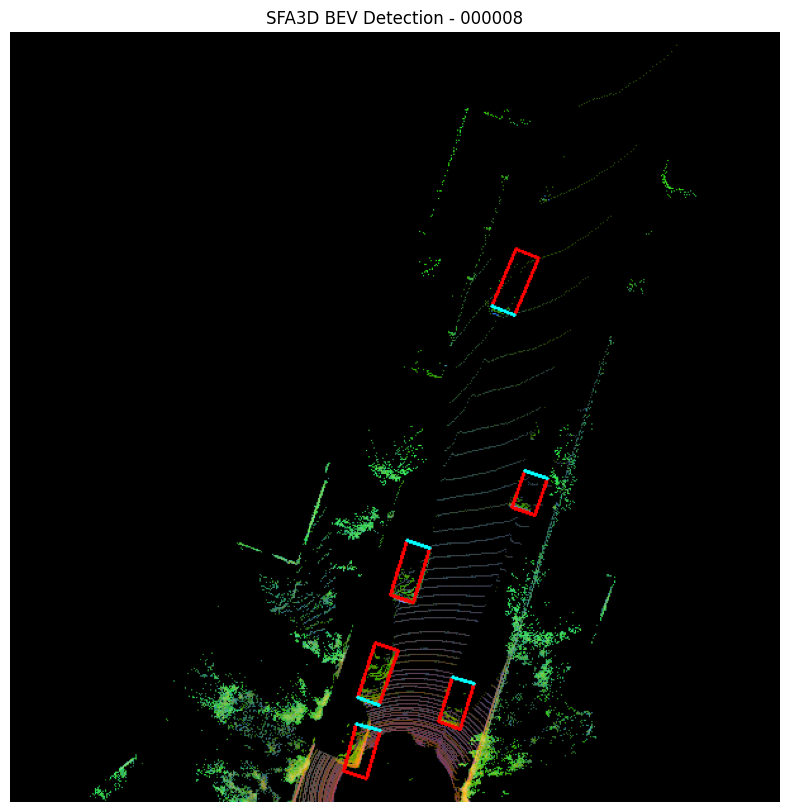

In [15]:
def main():

    # Load LiDAR
    points = load_lidar(SAMPLE_ID)

    # Load image
    image = load_image(SAMPLE_ID)

    # Create SFA3D BEV input
    bev, bev_visual = prepare_bev(points)

    # Load model
    model = create_model()

    # Run detection
    detections = detect(
        model,
        bev
    )

    # Convert detections to real LiDAR coordinates
    lidar_boxes = convert_to_lidar_boxes(
        detections[0]
    )

    # --------------------------------------------------------
    # Create 2D Bird's-Eye View visualization
    # --------------------------------------------------------

    # ============================================================
    # SFA3D BEV visualization
    # ============================================================
    
    bev_image = draw_predictions(
        bev_visual.copy(),
        detections[0].copy(),
        3
    )
    
    # ============================================================
    # Rotate exactly like original test.py
    # ============================================================
    
    bev_image = cv2.rotate(
        bev_image,
        cv2.ROTATE_180
    )
    
    # ============================================================
    # Display
    # ============================================================
    
    plt.figure(
        figsize=(10, 10)
    )
    
    plt.imshow(
        cv2.cvtColor(
            bev_image,
            cv2.COLOR_BGR2RGB
        )
    )
    
    plt.title(
        f"SFA3D BEV Detection - {SAMPLE_ID}"
    )
    
    plt.axis("off")
    
    plt.show()


if __name__ == "__main__":
    main()

In [16]:

# Load the verified original LiDAR scan
SAMPLE_ID = "003357"
original_points = load_lidar(SAMPLE_ID)

assert original_points.ndim == 2 and original_points.shape[1] == 4
print("Sample:", SAMPLE_ID)
print("Original LiDAR points:", len(original_points))

# Load SFA3D using the same checkpoint as the verified baseline
model = create_model()

# Clean baseline and three random point-dropout levels
conditions = [
    ("clean", 0.00),
    ("random_dropout", 0.20),
    ("random_dropout", 0.40),
    ("random_dropout", 0.60),
]

results = {}

for mode, severity in conditions:
    if mode == "clean":
        key = "clean"
    else:
        key = f"{mode}_{int(severity * 100)}"

    result = run_degraded_inference(
        model=model,
        original_points=original_points,
        mode=mode,
        severity=severity,
        seed=42
    )

    results[key] = result

    print(
        f"{key}: "
        f"input_points={len(result['points'])}, "
        f"predicted_boxes={len(result['boxes'])}"
    )


Sample: 003357
Original LiDAR points: 113679
Filtered LiDAR shape: (55601, 4)
Original BEV shape: (3, 608, 608)
clean: input_points=113679, predicted_boxes=7
Filtered LiDAR shape: (44511, 4)
Original BEV shape: (3, 608, 608)
random_dropout_20: input_points=91042, predicted_boxes=7
Filtered LiDAR shape: (33423, 4)
Original BEV shape: (3, 608, 608)
random_dropout_40: input_points=68406, predicted_boxes=7
Filtered LiDAR shape: (22274, 4)
Original BEV shape: (3, 608, 608)
random_dropout_60: input_points=45605, predicted_boxes=6


In [17]:

# Visualize predictions from the clean LiDAR scan
visualize_predictions_kaggle(
    results["clean"]["points"],
    results["clean"]["boxes"]
)

# Visualize predictions after 60% random point dropout
visualize_predictions_kaggle(
    results["random_dropout_60"]["points"],
    results["random_dropout_60"]["boxes"]
)


In [18]:

import os
import sys
import numpy as np

# --------------------------------------------------
# 1. Configure SFA3D import path
# --------------------------------------------------
SFA_ROOT = "/kaggle/working/SFA3D/sfa"

if SFA_ROOT not in sys.path:
    sys.path.insert(0, SFA_ROOT)

from data_process import transformation
from data_process.kitti_data_utils import Calibration
import config.kitti_config as cnf


# --------------------------------------------------
# 2. Load KITTI ground-truth boxes in LiDAR coordinates
# --------------------------------------------------
def load_sfa_ground_truth_lidar(sample_id):
    """
    Load KITTI ground-truth 3D boxes and convert them
    from camera coordinates to SFA3D LiDAR coordinates.

    Returns
    -------
    class_names : ndarray, shape (N,)
        KITTI class names for spatially filtered objects.

    lidar_boxes : ndarray, shape (N, 7)
        Boxes in [x, y, z, h, w, l, yaw] format.

        The z coordinate follows SFA3D's converted KITTI
        box convention and represents the box bottom center.
    """

    sample_id = str(sample_id).zfill(6)

    label_path = os.path.join(
        DATA_ROOT,
        "training",
        "label_2",
        f"{sample_id}.txt"
    )

    calib_path = os.path.join(
        DATA_ROOT,
        "training",
        "calib",
        f"{sample_id}.txt"
    )

    # Check required files
    if not os.path.isfile(label_path):
        raise FileNotFoundError(
            f"Label file not found: {label_path}"
        )

    if not os.path.isfile(calib_path):
        raise FileNotFoundError(
            f"Calibration file not found: {calib_path}"
        )

    calib = Calibration(calib_path)

    class_names = []
    camera_boxes = []

    # --------------------------------------------------
    # 3. Read KITTI labels
    # --------------------------------------------------
    with open(label_path, "r") as f:
        for line_number, line in enumerate(f, start=1):
            fields = line.split()

            if not fields:
                continue

            # KITTI label rows contain 15 required fields
            # before optional score fields.
            if len(fields) < 15:
                raise ValueError(
                    f"Malformed KITTI label at {label_path}, "
                    f"line {line_number}: expected at least "
                    f"15 fields, got {len(fields)}"
                )

            name = fields[0]

            # Preserve SFA3D's class filtering behavior
            if name not in cnf.CLASS_NAME_TO_ID:
                continue

            if int(cnf.CLASS_NAME_TO_ID[name]) <= -99:
                continue

            # KITTI fields:
            # h, w, l, x, y, z, rotation_y
            h, w, l = map(float, fields[8:11])
            x, y, z = map(float, fields[11:14])
            rotation_y = float(fields[14])

            class_names.append(name)

            camera_boxes.append([
                x, y, z,
                h, w, l,
                rotation_y
            ])

    # Handle samples with no eligible objects
    if not camera_boxes:
        return (
            np.array([], dtype=str),
            np.empty((0, 7), dtype=np.float32)
        )

    camera_boxes = np.asarray(
        camera_boxes,
        dtype=np.float32
    )

    # --------------------------------------------------
    # 4. Convert camera boxes to LiDAR coordinates
    # --------------------------------------------------
    lidar_boxes = transformation.camera_to_lidar_box(
        camera_boxes,
        calib.V2C,
        calib.R0,
        calib.P2
    ).astype(np.float32)

    # --------------------------------------------------
    # 5. Apply SFA3D spatial boundary filtering
    # --------------------------------------------------
    boundary = cnf.boundary
    centers = lidar_boxes[:, :3]

    keep = (
        (centers[:, 0] >= boundary["minX"]) &
        (centers[:, 0] < boundary["maxX"]) &
        (centers[:, 1] >= boundary["minY"]) &
        (centers[:, 1] < boundary["maxY"]) &
        (centers[:, 2] >= boundary["minZ"]) &
        (centers[:, 2] < boundary["maxZ"])
    )

    filtered_names = np.asarray(
        class_names,
        dtype=str
    )[keep]

    filtered_boxes = lidar_boxes[keep]

    return filtered_names, filtered_boxes


# --------------------------------------------------
# 6. Validate the loader on the verified sample
# --------------------------------------------------
SAMPLE_ID = "003357"

gt_names_all, gt_boxes_all = load_sfa_ground_truth_lidar(
    SAMPLE_ID
)

gt_boxes = gt_boxes_all[
    gt_names_all == "Car"
]

print(f"Sample ID: {SAMPLE_ID}")
print(f"Spatially filtered GT boxes: {len(gt_boxes_all)}")
print(f"GT Car boxes for evaluation: {len(gt_boxes)}")

print("\nGround-truth class counts:")
for name, count in zip(
    *np.unique(gt_names_all, return_counts=True)
):
    print(f"  {name}: {count}")

# Expected for your verified sample
assert len(gt_boxes_all) == 7, (
    f"Expected 7 spatially filtered boxes, "
    f"got {len(gt_boxes_all)}"
)

assert len(gt_boxes) == 6, (
    f"Expected 6 GT Cars, got {len(gt_boxes)}"
)

assert gt_boxes.shape == (6, 7)

print("\nGround-truth loader validated successfully.")


Sample ID: 003357
Spatially filtered GT boxes: 7
GT Car boxes for evaluation: 6

Ground-truth class counts:
  Car: 6
  Van: 1

Ground-truth loader validated successfully.


In [19]:

import numpy as np
from shapely.geometry import Polygon


def calculate_3d_iou(box1, box2):
    """
    Calculate oriented 3D Intersection over Union (IoU)
    for SFA3D/KITTI boxes.

    Expected box format:
        [x, y, z, h, w, l, yaw]

    Coordinate convention:
        x, y, z : box center in the horizontal plane and
                  bottom-center height in the vertical axis
        h, w, l : box height, width, and length
        yaw     : rotation around the LiDAR vertical axis

    Vertical bounds:
        z_min = z
        z_max = z + h

    Returns:
        float: 3D IoU in the range [0.0, 1.0].
    """

    box1 = np.asarray(box1, dtype=np.float64).reshape(-1)
    box2 = np.asarray(box2, dtype=np.float64).reshape(-1)

    if box1.size < 7 or box2.size < 7:
        raise ValueError(
            "Each box must contain at least "
            "[x, y, z, h, w, l, yaw]."
        )

    box1 = box1[:7]
    box2 = box2[:7]

    # Reject non-finite box parameters
    if not np.isfinite(box1).all() or not np.isfinite(box2).all():
        return 0.0

    x1, y1, z1, h1, w1, l1, yaw1 = box1
    x2, y2, z2, h2, w2, l2, yaw2 = box2

    # Invalid box dimensions
    if min(h1, w1, l1, h2, w2, l2) <= 0:
        return 0.0

    def footprint(x, y, w, l, yaw):
        """Create the rotated rectangular footprint in XY."""

        corners = np.array([
            [-l / 2, -w / 2],
            [ l / 2, -w / 2],
            [ l / 2,  w / 2],
            [-l / 2,  w / 2]
        ], dtype=np.float64)

        c = np.cos(yaw)
        s = np.sin(yaw)

        rotation = np.array([
            [c, -s],
            [s,  c]
        ])

        rotated = corners @ rotation.T
        rotated[:, 0] += x
        rotated[:, 1] += y

        return Polygon(rotated)

    poly1 = footprint(x1, y1, w1, l1, yaw1)
    poly2 = footprint(x2, y2, w2, l2, yaw2)

    if (
        not poly1.is_valid
        or not poly2.is_valid
        or poly1.is_empty
        or poly2.is_empty
    ):
        return 0.0

    # Intersection area in the horizontal XY plane
    intersection_area = poly1.intersection(poly2).area

    if intersection_area <= 0:
        return 0.0

    # Vertical overlap: z represents the bottom-center height
    z1_min, z1_max = z1, z1 + h1
    z2_min, z2_max = z2, z2 + h2

    intersection_height = max(
        0.0,
        min(z1_max, z2_max) - max(z1_min, z2_min)
    )

    if intersection_height <= 0:
        return 0.0

    intersection_volume = (
        intersection_area * intersection_height
    )

    volume1 = h1 * w1 * l1
    volume2 = h2 * w2 * l2

    union_volume = (
        volume1 + volume2 - intersection_volume
    )

    if union_volume <= 0:
        return 0.0

    iou = intersection_volume / union_volume

    return float(np.clip(iou, 0.0, 1.0))


# --------------------------------------------------
# Sanity checks
# --------------------------------------------------

# Identical boxes should have IoU approximately 1.0
test_box = np.array([
    10.0, 0.0, -1.5, 1.5, 1.6, 4.0, 0.2
])

identical_iou = calculate_3d_iou(test_box, test_box)

# Separate boxes should have IoU 0.0
separate_box = np.array([
    30.0, 0.0, -1.5, 1.5, 1.6, 4.0, 0.2
])

separate_iou = calculate_3d_iou(test_box, separate_box)

print("Identical-box IoU:", identical_iou)
print("Non-overlapping-box IoU:", separate_iou)

assert np.isclose(identical_iou, 1.0)
assert np.isclose(separate_iou, 0.0)




Identical-box IoU: 1.0
Non-overlapping-box IoU: 0.0


In [22]:

import numpy as np
from scipy.optimize import linear_sum_assignment

IOU_THRESHOLD = 0.50


def evaluate_condition(result, gt_boxes):
    """
    Evaluate Car detections against Car ground-truth boxes.

    Expected prediction format:
        result["boxes"]: [class_id, x, y, z, h, w, l, yaw]

    Expected GT format:
        gt_boxes: [x, y, z, h, w, l, yaw]

    Both prediction and GT boxes must use the same LiDAR
    coordinate convention as calculate_3d_iou().

    Returns:
        Dictionary containing detection metrics.
    """

    # --------------------------------------------------
    # 1. Extract and validate predicted boxes
    # --------------------------------------------------
    boxes = np.asarray(result.get("boxes", []), dtype=float)

    if boxes.size == 0:
        boxes = np.empty((0, 8), dtype=float)
    else:
        if boxes.size % 8 != 0:
            raise ValueError(
                "Predicted boxes must contain 8 values per box: "
                "[class_id, x, y, z, h, w, l, yaw]."
            )

        boxes = boxes.reshape(-1, 8)

    # SFA3D class ID 1 corresponds to Car in this setup
    pred_cars = boxes[boxes[:, 0] == 1, 1:8]

    # --------------------------------------------------
    # 2. Extract and validate ground-truth boxes
    # --------------------------------------------------
    gt_boxes = np.asarray(gt_boxes, dtype=float)

    if gt_boxes.size == 0:
        gt_boxes = np.empty((0, 7), dtype=float)
    else:
        if gt_boxes.size % 7 != 0:
            raise ValueError(
                "Ground-truth boxes must contain 7 values per box: "
                "[x, y, z, h, w, l, yaw]."
            )

        gt_boxes = gt_boxes.reshape(-1, 7)

    n_pred = len(pred_cars)
    n_gt = len(gt_boxes)

    # --------------------------------------------------
    # 3. Calculate pairwise 3D IoU
    # --------------------------------------------------
    iou_matrix = np.zeros((n_pred, n_gt), dtype=float)

    for i in range(n_pred):
        for j in range(n_gt):
            iou_matrix[i, j] = calculate_3d_iou(
                pred_cars[i],
                gt_boxes[j]
            )

    # --------------------------------------------------
    # 4. Hungarian matching
    # --------------------------------------------------
    if n_pred > 0 and n_gt > 0:
        valid_matches = iou_matrix >= IOU_THRESHOLD

        # Prioritize valid matches, then maximize their IoU.
        # The penalty exceeds the maximum possible total IoU
        # difference for any assignment.
        penalty = min(n_pred, n_gt) + 1.0

        cost_matrix = np.where(
            valid_matches,
            -penalty - iou_matrix,
            0.0
        )

        pred_idx, gt_idx = linear_sum_assignment(cost_matrix)

        matched_ious = iou_matrix[pred_idx, gt_idx]

        accepted_ious = matched_ious[
            matched_ious >= IOU_THRESHOLD
        ]

        true_positives = len(accepted_ious)

    else:
        accepted_ious = np.empty(0, dtype=float)
        true_positives = 0

    # --------------------------------------------------
    # 5. Calculate detection metrics
    # --------------------------------------------------
    false_positives = n_pred - true_positives
    false_negatives = n_gt - true_positives

    precision = (
        true_positives / n_pred
        if n_pred > 0 else 0.0
    )

    recall = (
        true_positives / n_gt
        if n_gt > 0 else 0.0
    )

    mean_iou = (
        float(np.mean(accepted_ious))
        if accepted_ious.size > 0 else 0.0
    )

    # This is the raw/degraded input point count, not the
    # number of points retained by SFA3D's BEV filtering.
    points_count = len(result.get("points", []))

    return {
        "points": points_count,
        "predictions": n_pred,
        "TP": true_positives,
        "FP": false_positives,
        "FN": false_negatives,
        "precision": precision,
        "recall": recall,
        "mean_matched_iou": mean_iou
    }




In [24]:

import os
import numpy as np

# --------------------------------------------------
# 1. Define KITTI directories
# --------------------------------------------------
label_dir = os.path.join(
    DATA_ROOT, "training", "label_2"
)
lidar_dir = os.path.join(
    DATA_ROOT, "training", "velodyne"
)
calib_dir = os.path.join(
    DATA_ROOT, "training", "calib"
)

# --------------------------------------------------
# 2. Validate directories
# --------------------------------------------------
for directory in [label_dir, lidar_dir, calib_dir]:
    if not os.path.isdir(directory):
        raise FileNotFoundError(
            f"Required KITTI directory not found: {directory}"
        )

# --------------------------------------------------
# 3. Find matching sample IDs
# --------------------------------------------------
label_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(label_dir)
    if f.endswith(".txt")
}

lidar_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(lidar_dir)
    if f.endswith(".bin")
}

calib_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(calib_dir)
    if f.endswith(".txt")
}

available_ids = sorted(
    label_ids & lidar_ids & calib_ids
)

# --------------------------------------------------
# 4. Reproducibly select 500 unique frames
# --------------------------------------------------
N_FRAMES = 500
SEED = 42

if len(available_ids) < N_FRAMES:
    raise ValueError(
        f"Only {len(available_ids)} complete frames available; "
        f"{N_FRAMES} required."
    )

rng = np.random.default_rng(SEED)

selected_samples = sorted(
    rng.choice(
        available_ids,
        size=N_FRAMES,
        replace=False
    ).tolist()
)

# --------------------------------------------------
# 5. Report selection summary
# --------------------------------------------------
print("Available complete frames:", len(available_ids))
print("Selected frames:", len(selected_samples))
print("Unique selected frames:", len(set(selected_samples)))


assert len(selected_samples) == N_FRAMES
assert len(set(selected_samples)) == N_FRAMES

print("Frame selection completed successfully.")


Available complete frames: 7481
Selected frames: 500
Unique selected frames: 500
Frame selection completed successfully.


In [25]:

import os
import io
import numpy as np
import pandas as pd
from contextlib import redirect_stdout

conditions = [
    ("clean", 0.00, "Clean"),
    ("random_dropout", 0.20, "Random dropout 20%"),
    ("random_dropout", 0.40, "Random dropout 40%"),
    ("random_dropout", 0.60, "Random dropout 60%"),
    ("coordinate_noise", 0.05, "Coordinate noise 0.05 m"),
    ("coordinate_noise", 0.10, "Coordinate noise 0.10 m"),
    ("coordinate_noise", 0.20, "Coordinate noise 0.20 m"),
]

# Set this to 100 if selected_samples contains only 100 frames.
N_FRAMES = len(selected_samples)

results_path = (
    f"/kaggle/working/lidar_robustness_{N_FRAMES}_frames.csv"
)

frame_rows = []

# Start a fresh evaluation; this overwrites the CSV at results_path.
for frame_number, sample_id in enumerate(selected_samples, start=1):

    # Load this frame's original LiDAR point cloud.
    points = load_lidar(sample_id)
    points = np.asarray(points, dtype=np.float32)

    if points.ndim != 2 or points.shape[1] != 4:
        raise ValueError(
            f"Unexpected LiDAR shape for {sample_id}: {points.shape}"
        )

    original_point_count = len(points)

    # Load ground-truth boxes and evaluate Cars only.
    gt_classes, gt_boxes_all = load_sfa_ground_truth_lidar(sample_id)

    gt_classes = np.asarray(gt_classes)
    gt_boxes_all = np.asarray(gt_boxes_all)

    if len(gt_classes) != len(gt_boxes_all):
        raise ValueError(
            f"Ground-truth class/box mismatch for {sample_id}: "
            f"{len(gt_classes)} classes vs {len(gt_boxes_all)} boxes"
        )

    car_mask = gt_classes == "Car"
    gt_boxes = gt_boxes_all[car_mask]

    # Deterministic seed for this frame, shared across its conditions.
    seed = 42 + int(sample_id)

    for mode, severity, condition_name in conditions:

        with redirect_stdout(io.StringIO()):
            result = run_degraded_inference(
                model=model,
                original_points=points,
                mode=mode,
                severity=severity,
                seed=seed,
            )

        metrics = evaluate_condition(result, gt_boxes)

        frame_rows.append({
            "sample_id": sample_id,
            "condition": condition_name,
            "input_points": original_point_count,
            "degraded_points": len(result["points"]),
            "ground_truth_cars": len(gt_boxes),
            **{
                key: value
                for key, value in metrics.items()
                if key != "points"
            },
        })

    # Save progress after each completed frame.
    pd.DataFrame(frame_rows).to_csv(results_path, index=False)

    if frame_number % 25 == 0 or frame_number == N_FRAMES:
        print(
            f"Processed {frame_number}/{N_FRAMES} frames | "
            f"Evaluations: {len(frame_rows)}"
        )

multi_frame_df = pd.DataFrame(frame_rows)

print("\nEvaluation completed.")
print("Frames:", multi_frame_df["sample_id"].nunique())
print("Conditions:", multi_frame_df["condition"].nunique())
print("Evaluations:", len(multi_frame_df))
print("Expected evaluations:", N_FRAMES * len(conditions))

assert multi_frame_df["sample_id"].nunique() == N_FRAMES
assert len(multi_frame_df) == N_FRAMES * len(conditions)
assert not multi_frame_df.duplicated(
    subset=["sample_id", "condition"]
).any()

display(multi_frame_df.head())


Processed 25/500 frames | Evaluations: 175
Processed 50/500 frames | Evaluations: 350
Processed 75/500 frames | Evaluations: 525
Processed 100/500 frames | Evaluations: 700
Processed 125/500 frames | Evaluations: 875
Processed 150/500 frames | Evaluations: 1050
Processed 175/500 frames | Evaluations: 1225
Processed 200/500 frames | Evaluations: 1400
Processed 225/500 frames | Evaluations: 1575
Processed 250/500 frames | Evaluations: 1750
Processed 275/500 frames | Evaluations: 1925
Processed 300/500 frames | Evaluations: 2100
Processed 325/500 frames | Evaluations: 2275
Processed 350/500 frames | Evaluations: 2450
Processed 375/500 frames | Evaluations: 2625
Processed 400/500 frames | Evaluations: 2800
Processed 425/500 frames | Evaluations: 2975
Processed 450/500 frames | Evaluations: 3150
Processed 475/500 frames | Evaluations: 3325
Processed 500/500 frames | Evaluations: 3500

Evaluation completed.
Frames: 500
Conditions: 7
Evaluations: 3500
Expected evaluations: 3500


,sample_id,condition,input_points,degraded_points,ground_truth_cars,predictions,TP,FP,FN,precision,recall,mean_matched_iou
0,000039,Clean,111670,111670,6,6,1,5,5,0.166667,0.166667,0.586038
1,000039,Random dropout 20%,111670,89379,6,6,4,2,2,0.666667,0.666667,0.536318
2,000039,Random dropout 40%,111670,67030,6,6,4,2,2,0.666667,0.666667,0.737141
3,000039,Random dropout 60%,111670,44738,6,4,2,2,4,0.500000,0.333333,0.650676
4,000039,Coordinate noise 0.05 m,111670,111670,6,6,1,5,5,0.166667,0.166667,0.715648


In [29]:

import pandas as pd
import numpy as np

results_path = "/kaggle/working/lidar_robustness_500_frames.csv"

multi_frame_df = pd.read_csv(
    results_path,
    dtype={"sample_id": str}
)

# Normalize KITTI frame IDs.
multi_frame_df["sample_id"] = (
    multi_frame_df["sample_id"].str.zfill(6)
)

# Expected experiment structure.
expected_conditions = 7
expected_frames = multi_frame_df["sample_id"].nunique()

print("Frames:", expected_frames)
print("Conditions:", multi_frame_df["condition"].nunique())
print("Total evaluations:", len(multi_frame_df))
print("Expected evaluations:", expected_frames * expected_conditions)

# Validate the actual experiment.
assert expected_frames == 500, (
    f"Expected 500 frames, found {expected_frames}"
)
assert multi_frame_df["condition"].nunique() == expected_conditions
assert len(multi_frame_df) == expected_frames * expected_conditions
assert not multi_frame_df.duplicated(
    subset=["sample_id", "condition"]
).any()

# Support both earlier and revised column names.
input_col = (
    "input_points"
    if "input_points" in multi_frame_df.columns
    else "original_points"
)

retained_col = (
    "degraded_points"
    if "degraded_points" in multi_frame_df.columns
    else "retained_points"
)

# Aggregate counts and per-frame averages.
aggregate_df = (
    multi_frame_df
    .groupby("condition", sort=False)
    .agg(
        frames=("sample_id", "nunique"),
        ground_truth_cars=("ground_truth_cars", "sum"),
        predictions=("predictions", "sum"),
        TP=("TP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum"),
        mean_frame_precision=("precision", "mean"),
        mean_frame_recall=("recall", "mean"),
        mean_original_points=(input_col, "mean"),
        mean_degraded_points=(retained_col, "mean"),
    )
    .reset_index()
)

# Pooled dataset-level precision and recall.
aggregate_df["precision"] = (
    aggregate_df["TP"] /
    (aggregate_df["TP"] + aggregate_df["FP"]).replace(0, np.nan)
)

aggregate_df["recall"] = (
    aggregate_df["TP"] /
    (aggregate_df["TP"] + aggregate_df["FN"]).replace(0, np.nan)
)

# TP-weighted mean matched IoU.
if "mean_matched_iou" in multi_frame_df.columns:
    valid_iou = multi_frame_df["TP"] > 0

    iou_rows = multi_frame_df.loc[valid_iou].copy()
    iou_rows["_iou_sum"] = (
        iou_rows["mean_matched_iou"] * iou_rows["TP"]
    )

    iou_summary = (
        iou_rows.groupby("condition", sort=False)
        .agg(
            _iou_sum=("_iou_sum", "sum"),
            _matched_count=("TP", "sum"),
        )
        .reset_index()
    )

    iou_summary["mean_matched_iou"] = (
        iou_summary["_iou_sum"] /
        iou_summary["_matched_count"].replace(0, np.nan)
    )

    aggregate_df = aggregate_df.merge(
        iou_summary[["condition", "mean_matched_iou"]],
        on="condition",
        how="left",
        validate="one_to_one",
    )

print("Validation passed: 500 frames × 7 conditions = 3,500 evaluations.")

display(aggregate_df.round(4))


Frames: 500
Conditions: 7
Total evaluations: 3500
Expected evaluations: 3500
Validation passed: 500 frames × 7 conditions = 3,500 evaluations.


,condition,frames,ground_truth_cars,predictions,TP,FP,FN,mean_frame_precision,mean_frame_recall,mean_original_points,mean_degraded_points,precision,recall,mean_matched_iou
0,Clean,500,1639,1780,962,818,677,0.4553,0.4829,119412.65,119412.650,0.5404,0.5869,0.6649
1,Random dropout 20%,500,1639,1782,931,851,708,0.4464,0.4766,119412.65,95545.198,0.5224,0.5680,0.6597
2,Random dropout 40%,500,1639,1775,891,884,748,0.4246,0.4504,119412.65,71658.966,0.5020,0.5436,0.6567
3,Random dropout 60%,500,1639,1606,818,788,821,0.4298,0.4237,119412.65,47779.188,0.5093,0.4991,0.6482
4,Coordinate noise 0.05 m,500,1639,1780,895,885,744,0.4373,0.4638,119412.65,119412.650,0.5028,0.5461,0.6552
5,Coordinate noise 0.10 m,500,1639,1677,831,846,808,0.4161,0.4305,119412.65,119412.650,0.4955,0.5070,0.6360
6,Coordinate noise 0.20 m,500,1639,760,367,393,1272,0.3252,0.2022,119412.65,119412.650,0.4829,0.2239,0.6057


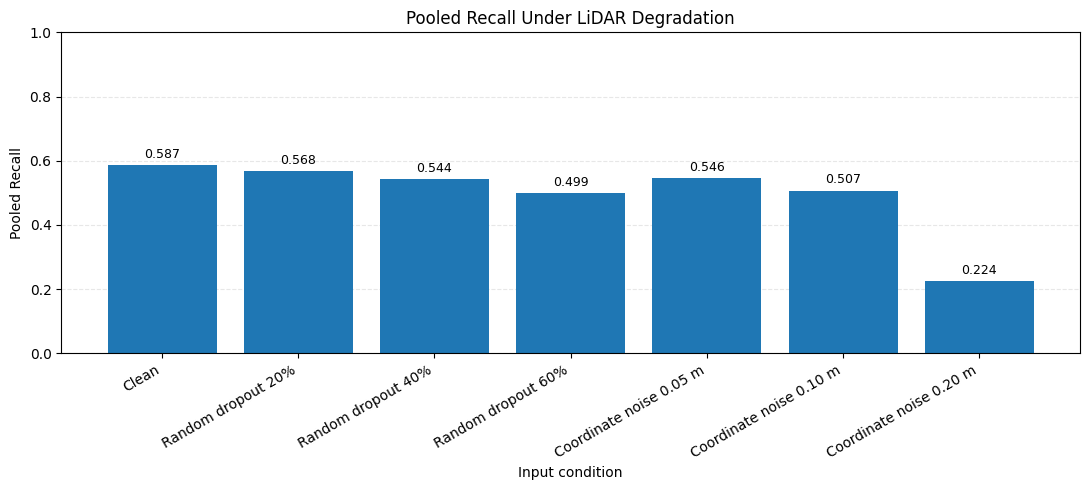

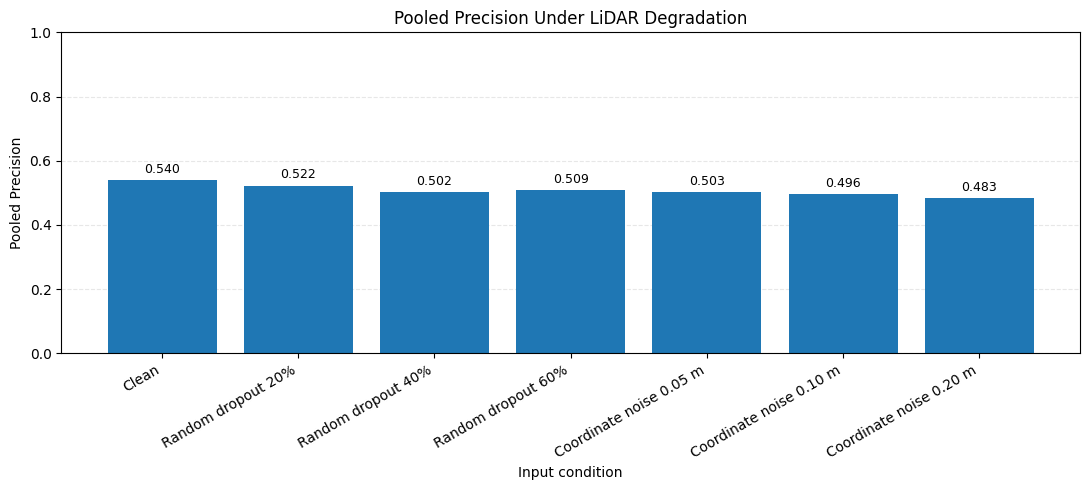

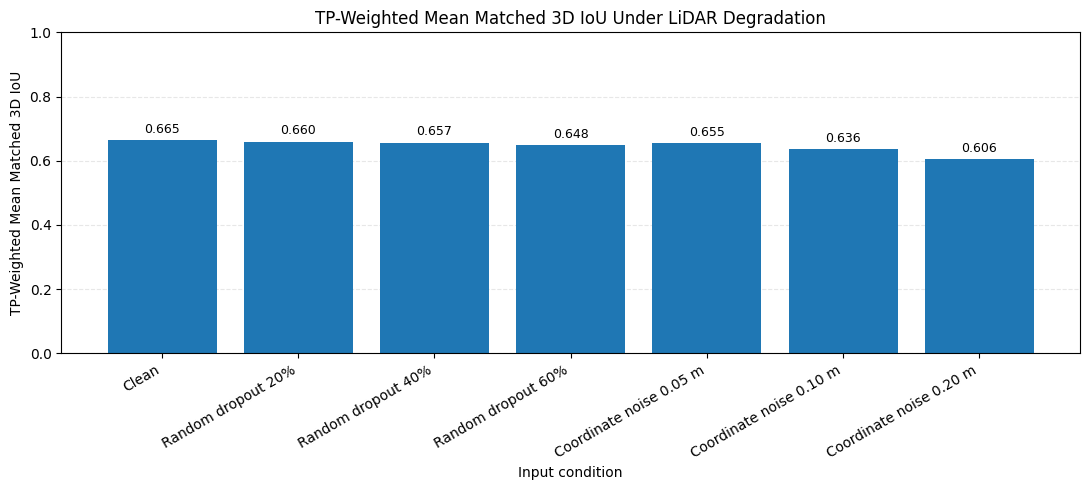

In [30]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

condition_order = [
    "Clean",
    "Random dropout 20%",
    "Random dropout 40%",
    "Random dropout 60%",
    "Coordinate noise 0.05 m",
    "Coordinate noise 0.10 m",
    "Coordinate noise 0.20 m",
]

plot_df = (
    aggregate_df
    .set_index("condition")
    .reindex(condition_order)
    .reset_index()
)

# Verify that every requested condition is present.
missing_conditions = plot_df.loc[
    plot_df["TP"].isna(), "condition"
].tolist()

if missing_conditions:
    raise ValueError(
        f"Missing conditions in aggregate_df: {missing_conditions}"
    )

metrics_to_plot = [
    ("recall", "Pooled Recall"),
    ("precision", "Pooled Precision"),
    ("mean_matched_iou", "TP-Weighted Mean Matched 3D IoU"),
]

for column, title in metrics_to_plot:
    values = pd.to_numeric(plot_df[column], errors="coerce")

    fig, ax = plt.subplots(figsize=(11, 5))
    bars = ax.bar(plot_df["condition"], values)

    ax.set_title(f"{title} Under LiDAR Degradation")
    ax.set_ylabel(title)
    ax.set_xlabel("Input condition")
    ax.set_ylim(0, 1)
    ax.set_xticks(range(len(condition_order)))
    ax.set_xticklabels(condition_order, rotation=30, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Display values above valid bars.
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.annotate(
                f"{value:.3f}",
                xy=(bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
            )

    plt.tight_layout()
    plt.show()


In [32]:

import pandas as pd
import numpy as np

input_path = "/kaggle/working/lidar_robustness_500_frames.csv"
output_path = "/kaggle/working/lidar_robustness_final_summary.csv"

df = pd.read_csv(input_path, dtype={"sample_id": str})
df["sample_id"] = df["sample_id"].str.zfill(6)

# Support either version of the evaluation CSV.
input_col = (
    "input_points" if "input_points" in df.columns
    else "original_points"
)
retained_col = (
    "degraded_points" if "degraded_points" in df.columns
    else "retained_points"
)

required_columns = [
    "sample_id", "condition", "TP", "FP", "FN",
    "ground_truth_cars", "mean_matched_iou",
    input_col, retained_col,
]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df.duplicated(["sample_id", "condition"]).any():
    raise ValueError("Duplicate frame-condition evaluations found.")

rows = []

for condition, group in df.groupby("condition", sort=False):
    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())

    gt_cars = int(group["ground_truth_cars"].sum())
    predictions = tp + fp

    precision = tp / predictions if predictions else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan

    # TP-weighted matched IoU across all frames.
    iou_sum = (group["mean_matched_iou"] * group["TP"]).sum()
    mean_iou = iou_sum / tp if tp else np.nan

    total_points = group[input_col].sum()
    retained_points = group[retained_col].sum()

    rows.append({
        "Condition": condition,
        "Frames": group["sample_id"].nunique(),
        "GT cars": gt_cars,
        "Predictions": predictions,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Mean matched 3D IoU": mean_iou,
        "Points retained (%)": (
            100 * retained_points / total_points
            if total_points > 0 else np.nan
        ),
    })

results = pd.DataFrame(rows)

clean_rows = results.loc[results["Condition"] == "Clean", "Recall"]

if len(clean_rows) != 1:
    raise ValueError(
        "Expected exactly one Clean condition in the summary."
    )

baseline_recall = clean_rows.iloc[0]

results["Recall change (pp)"] = (
    (results["Recall"] - baseline_recall) * 100
)

if pd.notna(baseline_recall) and baseline_recall > 0:
    results["Recall reduction (%)"] = (
        (baseline_recall - results["Recall"])
        / baseline_recall * 100
    )
else:
    results["Recall reduction (%)"] = np.nan

display(results.round(3))

results.to_csv(output_path, index=False)
print("Saved final summary to:", output_path)


,Condition,Frames,GT cars,Predictions,TP,FP,FN,Precision,Recall,Mean matched 3D IoU,Points retained (%),Recall change (pp),Recall reduction (%)
0,Clean,500,1639,1780,962,818,677,0.540,0.587,0.665,100.000,0.000,0.000
1,Random dropout 20%,500,1639,1782,931,851,708,0.522,0.568,0.660,80.013,-1.891,3.222
2,Random dropout 40%,500,1639,1775,891,884,748,0.502,0.544,0.657,60.010,-4.332,7.380
3,Random dropout 60%,500,1639,1606,818,788,821,0.509,0.499,0.648,40.012,-8.786,14.969
4,Coordinate noise 0.05 m,500,1639,1780,895,885,744,0.503,0.546,0.655,100.000,-4.088,6.965
5,Coordinate noise 0.10 m,500,1639,1677,831,846,808,0.496,0.507,0.636,100.000,-7.993,13.617
6,Coordinate noise 0.20 m,500,1639,760,367,393,1272,0.483,0.224,0.606,100.000,-36.303,61.850


Saved final summary to: /kaggle/working/lidar_robustness_final_summary.csv


In [35]:

import os
import numpy as np
import pandas as pd

results_path = "/kaggle/working/lidar_robustness_500_frames.csv"
summary_path = "/kaggle/working/lidar_robustness_500_frames_summary.csv"

if not os.path.exists(results_path):
    raise FileNotFoundError(
        f"{results_path} does not exist. "
        "Run and save the actual 500-frame evaluation first."
    )

df = pd.read_csv(results_path, dtype={"sample_id": str})
df["sample_id"] = df["sample_id"].str.zfill(6)

# Support either naming convention from the evaluation loop.
points_col = (
    "input_points" if "input_points" in df.columns
    else "original_points"
)
retained_col = (
    "degraded_points" if "degraded_points" in df.columns
    else "retained_points"
)

required = [
    "sample_id", "condition", "predictions", "TP", "FP", "FN",
    "ground_truth_cars", "mean_matched_iou",
    points_col, retained_col,
]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing CSV columns: {missing}")

# 1. Validate completeness and uniqueness.
expected_frames = 500
expected_conditions = 7

print("Unique frames:", df["sample_id"].nunique())
print("Conditions:", df["condition"].nunique())
print("Evaluation rows:", len(df))

assert df["sample_id"].nunique() == expected_frames, (
    "Expected 500 frames. Confirm the actual 500-frame run completed."
)
assert df["condition"].nunique() == expected_conditions
assert len(df) == expected_frames * expected_conditions
assert not df.duplicated(["sample_id", "condition"]).any()

# 2. Validate count consistency.
assert (df["predictions"] == df["TP"] + df["FP"]).all()
assert (df["ground_truth_cars"] == df["TP"] + df["FN"]).all()

# 3. Calculate dataset-level pooled metrics.
summary = (
    df.groupby("condition", sort=False)
    .agg(
        frames=("sample_id", "nunique"),
        GT_cars=("ground_truth_cars", "sum"),
        predictions=("predictions", "sum"),
        TP=("TP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum"),
        mean_original_points=(points_col, "mean"),
        mean_degraded_points=(retained_col, "mean"),
    )
    .reset_index()
)

summary["precision"] = (
    summary["TP"] /
    (summary["TP"] + summary["FP"]).replace(0, np.nan)
)

summary["recall"] = (
    summary["TP"] /
    (summary["TP"] + summary["FN"]).replace(0, np.nan)
)

# TP-weighted mean matched IoU.
iou_df = df.assign(
    _iou_sum=df["mean_matched_iou"] * df["TP"]
)

iou_summary = (
    iou_df.groupby("condition", sort=False)
    .agg(
        _iou_sum=("_iou_sum", "sum"),
        _matched_count=("TP", "sum"),
    )
    .reset_index()
)

iou_summary["mean_matched_3d_iou"] = (
    iou_summary["_iou_sum"] /
    iou_summary["_matched_count"].replace(0, np.nan)
)

summary = summary.merge(
    iou_summary[["condition", "mean_matched_3d_iou"]],
    on="condition",
    validate="one_to_one",
)

summary["points_retained_pct"] = (
    100 * summary["mean_degraded_points"] /
    summary["mean_original_points"].replace(0, np.nan)
)

# 4. Compare recall with the Clean baseline.
clean_rows = summary.loc[summary["condition"] == "Clean", "recall"]

if len(clean_rows) != 1:
    raise ValueError("Expected exactly one Clean condition.")

clean_recall = clean_rows.iloc[0]

summary["recall_change_pp"] = (
    summary["recall"] - clean_recall
) * 100

if pd.notna(clean_recall) and clean_recall > 0:
    summary["recall_reduction_pct"] = (
        (clean_recall - summary["recall"]) /
        clean_recall * 100
    )
else:
    summary["recall_reduction_pct"] = np.nan

display(summary.round(4))

summary.to_csv(summary_path, index=False)


Unique frames: 500
Conditions: 7
Evaluation rows: 3500


,condition,frames,GT_cars,predictions,TP,FP,FN,mean_original_points,mean_degraded_points,precision,recall,mean_matched_3d_iou,points_retained_pct,recall_change_pp,recall_reduction_pct
0,Clean,500,1639,1780,962,818,677,119412.65,119412.650,0.5404,0.5869,0.6649,100.0000,0.0000,0.0000
1,Random dropout 20%,500,1639,1782,931,851,708,119412.65,95545.198,0.5224,0.5680,0.6597,80.0126,-1.8914,3.2225
2,Random dropout 40%,500,1639,1775,891,884,748,119412.65,71658.966,0.5020,0.5436,0.6567,60.0095,-4.3319,7.3805
3,Random dropout 60%,500,1639,1606,818,788,821,119412.65,47779.188,0.5093,0.4991,0.6482,40.0118,-8.7858,14.9688
4,Coordinate noise 0.05 m,500,1639,1780,895,885,744,119412.65,119412.650,0.5028,0.5461,0.6552,100.0000,-4.0879,6.9647
5,Coordinate noise 0.10 m,500,1639,1677,831,846,808,119412.65,119412.650,0.4955,0.5070,0.6360,100.0000,-7.9927,13.6175
6,Coordinate noise 0.20 m,500,1639,760,367,393,1272,119412.65,119412.650,0.4829,0.2239,0.6057,100.0000,-36.3026,61.8503


In [33]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/working/lidar_robustness_500_frames.csv")

clean = df[df["condition"] == "Clean"].copy()
noisy = df[df["condition"] == "Coordinate noise 0.20 m"].copy()

# Keep one row per sample and condition.
assert not clean["sample_id"].duplicated().any(), "Duplicate clean sample IDs"
assert not noisy["sample_id"].duplicated().any(), "Duplicate noisy sample IDs"

paired = clean.merge(
    noisy,
    on="sample_id",
    how="inner",
    suffixes=("_clean", "_noisy"),
    validate="one_to_one"
)

# Recompute per-frame recall and changes from raw counts.
paired["clean_recall"] = (
    paired["TP_clean"] /
    (paired["TP_clean"] + paired["FN_clean"]).replace(0, np.nan)
)

paired["noisy_recall"] = (
    paired["TP_noisy"] /
    (paired["TP_noisy"] + paired["FN_noisy"]).replace(0, np.nan)
)

paired["recall_drop_pp"] = (
    paired["clean_recall"] - paired["noisy_recall"]
) * 100

paired["additional_missed_cars"] = (
    paired["FN_noisy"] - paired["FN_clean"]
)

paired["additional_false_positives"] = (
    paired["FP_noisy"] - paired["FP_clean"]
)

# Verify that the raw counts agree with the GT count in each condition.
paired["clean_count_valid"] = (
    paired["TP_clean"] + paired["FN_clean"]
    == paired["ground_truth_cars_clean"]
)

paired["noisy_count_valid"] = (
    paired["TP_noisy"] + paired["FN_noisy"]
    == paired["ground_truth_cars_noisy"]
)

print("Paired frames:", len(paired))
print("Invalid clean count rows:", (~paired["clean_count_valid"]).sum())
print("Invalid noisy count rows:", (~paired["noisy_count_valid"]).sum())

# Inspect the worst recall degradations first.
failure_columns = [
    "sample_id",
    "ground_truth_cars_clean",
    "TP_clean", "FP_clean", "FN_clean",
    "TP_noisy", "FP_noisy", "FN_noisy",
    "clean_recall", "noisy_recall", "recall_drop_pp",
    "additional_missed_cars", "additional_false_positives",
    "clean_count_valid", "noisy_count_valid"
]

worst = paired.sort_values(
    ["recall_drop_pp", "additional_missed_cars"],
    ascending=[False, False]
)[failure_columns]

display(worst.head(25))

Paired frames: 500
Invalid clean count rows: 0
Invalid noisy count rows: 0


,sample_id,ground_truth_cars_clean,TP_clean,FP_clean,FN_clean,TP_noisy,FP_noisy,FN_noisy,clean_recall,noisy_recall,recall_drop_pp,additional_missed_cars,additional_false_positives,clean_count_valid,noisy_count_valid
228,3357,6,6,1,0,0,0,6,1.0,0.0,100.0,6,-1,True,True
341,5132,5,5,0,0,0,2,5,1.0,0.0,100.0,5,2,True,True
86,1268,4,4,0,0,0,0,4,1.0,0.0,100.0,4,0,True,True
400,5884,3,3,0,0,0,1,3,1.0,0.0,100.0,3,1,True,True
477,7152,3,3,0,0,0,2,3,1.0,0.0,100.0,3,2,True,True
19,308,2,2,0,0,0,1,2,1.0,0.0,100.0,2,1,True,True
92,1324,2,2,0,0,0,0,2,1.0,0.0,100.0,2,0,True,True
144,2191,2,2,0,0,0,1,2,1.0,0.0,100.0,2,1,True,True
153,2296,2,2,0,0,0,0,2,1.0,0.0,100.0,2,0,True,True
170,2582,2,2,0,0,0,0,2,1.0,0.0,100.0,2,0,True,True


Frame: 000308
Original point cloud shape: (123961, 4)
Filtered LiDAR shape: (59578, 4)
Original BEV shape: (3, 608, 608)
Noisy point cloud shape: (123961, 4)


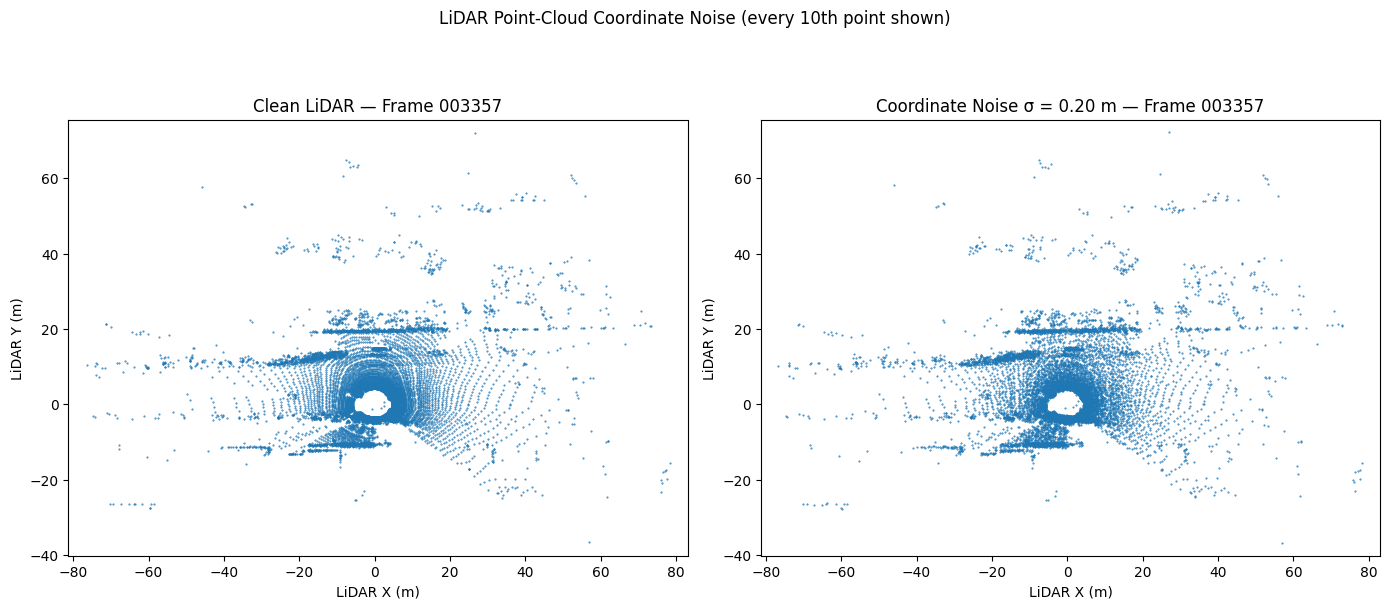

In [34]:

import numpy as np
import matplotlib.pyplot as plt

sample_id = "000308"

# Load original LiDAR points.
points = np.asarray(load_lidar(sample_id), dtype=np.float32)

print("Frame:", sample_id)
print("Original point cloud shape:", points.shape)

# Reproduce the deterministic corruption used in the evaluation.
seed = 42 + int(sample_id)

degraded = run_degraded_inference(
    model=model,
    original_points=points.copy(),
    mode="coordinate_noise",
    severity=0.20,
    seed=seed,
)

noisy_points = np.asarray(degraded["points"])

print("Noisy point cloud shape:", noisy_points.shape)

# Subsample for plotting only; inference used the full point cloud.
plot_step = 10
clean_plot = points[::plot_step]
noisy_plot = noisy_points[::plot_step]

# Use common axis limits for a fair visual comparison.
x_min = min(clean_plot[:, 0].min(), noisy_plot[:, 0].min())
x_max = max(clean_plot[:, 0].max(), noisy_plot[:, 0].max())
y_min = min(clean_plot[:, 1].min(), noisy_plot[:, 1].min())
y_max = max(clean_plot[:, 1].max(), noisy_plot[:, 1].max())

x_pad = max((x_max - x_min) * 0.03, 1.0)
y_pad = max((y_max - y_min) * 0.03, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(
    clean_plot[:, 0], clean_plot[:, 1],
    s=0.2
)
axes[0].set_title("Clean LiDAR — Frame 003357")
axes[0].set_xlabel("LiDAR X (m)")
axes[0].set_ylabel("LiDAR Y (m)")
axes[0].set_aspect("equal", adjustable="box")

axes[1].scatter(
    noisy_plot[:, 0], noisy_plot[:, 1],
    s=0.2
)
axes[1].set_title("Coordinate Noise σ = 0.20 m — Frame 003357")
axes[1].set_xlabel("LiDAR X (m)")
axes[1].set_ylabel("LiDAR Y (m)")
axes[1].set_aspect("equal", adjustable="box")

for ax in axes:
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    ax.grid(False)

fig.suptitle(
    "LiDAR Point-Cloud Coordinate Noise (every 10th point shown)",
    y=1.02
)
plt.tight_layout()
plt.show()


In [36]:

import numpy as np
import pandas as pd

# Extract Car predictions from the existing inference results.
def get_car_boxes(result):
    boxes = np.asarray(result["boxes"], dtype=float)

    if boxes.size == 0:
        return np.empty((0, 7), dtype=float)

    boxes = boxes.reshape(-1, 8)
    car_id = int(cnf.CLASS_NAME_TO_ID["Car"])

    return boxes[boxes[:, 0].astype(int) == car_id, 1:8]


clean_cars = get_car_boxes(clean_result)
noisy_cars = get_car_boxes(noisy_result)

def inspect_matches(pred_boxes, gt_boxes):
    rows = []

    for pred_idx, pred in enumerate(pred_boxes):
        for gt_idx, gt in enumerate(gt_boxes):
            iou = calculate_3d_iou(pred, gt)

            rows.append({
                "prediction": pred_idx,
                "ground_truth": gt_idx,
                "3D_IoU": iou,
                "matched_at_0.50": iou >= 0.50
            })

    return pd.DataFrame(
        rows,
        columns=[
            "prediction", "ground_truth",
            "3D_IoU", "matched_at_0.50"
        ]
    )

print("Clean predicted cars:", len(clean_cars))
print("Noisy predicted cars:", len(noisy_cars))
print("Ground-truth cars:", len(gt_boxes))

print("\nCLEAN PREDICTIONS")
display(inspect_matches(clean_cars, gt_boxes))

print("\nNOISY PREDICTIONS")
display(inspect_matches(noisy_cars, gt_boxes))


Clean predicted cars: 2
Noisy predicted cars: 1
Ground-truth cars: 2

CLEAN PREDICTIONS


,prediction,ground_truth,3D_IoU,matched_at_0.50
0,0,0,0.549334,True
1,0,1,0.000000,False
2,1,0,0.000000,False
3,1,1,0.531406,True



NOISY PREDICTIONS


,prediction,ground_truth,3D_IoU,matched_at_0.50
0,0,0,0.000000,False
1,0,1,0.253171,False


In [37]:
sample_id = "000308"
noise_severity = 0.20
seed = 42 + int(sample_id)

points = np.asarray(load_lidar(sample_id), dtype=np.float32)

gt_classes, gt_boxes_all = load_sfa_ground_truth_lidar(sample_id)
gt_classes = np.asarray(gt_classes)
gt_boxes_all = np.asarray(gt_boxes_all)
gt_boxes = gt_boxes_all[gt_classes == "Car"]

clean_result = run_degraded_inference(
    model=model,
    original_points=points.copy(),
    mode="clean",
    severity=0.0,
    seed=seed,
)

noisy_result = run_degraded_inference(
    model=model,
    original_points=points.copy(),
    mode="coordinate_noise",
    severity=noise_severity,
    seed=seed,
)

clean_cars = get_car_boxes(clean_result)
noisy_cars = get_car_boxes(noisy_result)

print("Frame:", sample_id)
print("Ground-truth cars:", len(gt_boxes))
print("Clean predicted cars:", len(clean_cars))
print("Noisy predicted cars:", len(noisy_cars))
print("Clean raw points:", len(clean_result["points"]))
print("Noisy raw points:", len(noisy_result["points"]))

Filtered LiDAR shape: (59703, 4)
Original BEV shape: (3, 608, 608)
Filtered LiDAR shape: (59578, 4)
Original BEV shape: (3, 608, 608)
Frame: 000308
Ground-truth cars: 2
Clean predicted cars: 2
Noisy predicted cars: 1
Clean raw points: 123961
Noisy raw points: 123961


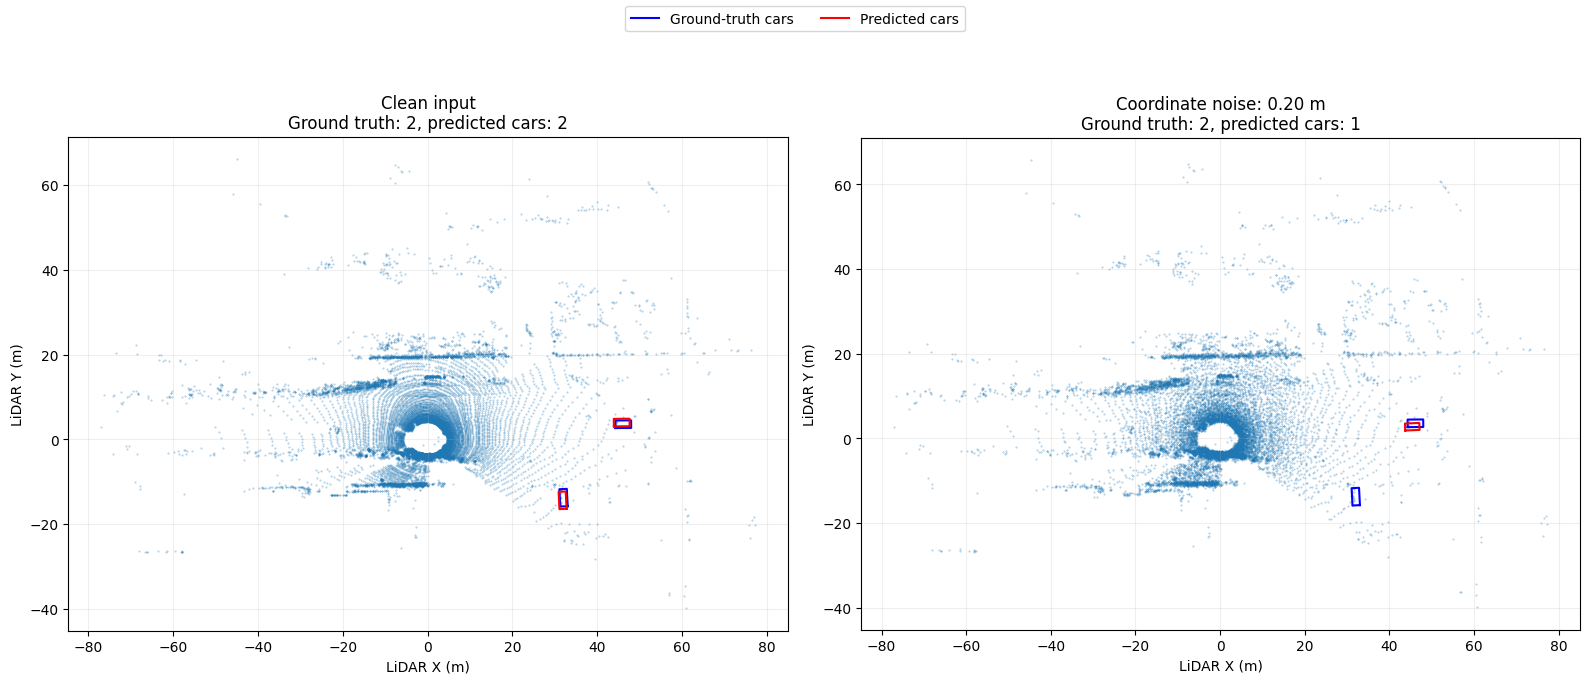

In [38]:

from matplotlib.lines import Line2D

def draw_box_bev(ax, box, color, linewidth=1.5):
    """
    Draw one oriented box in BEV.
    Accepts either [x,y,z,h,w,l,yaw] or
    [class_id,x,y,z,h,w,l,yaw].
    """
    box = np.asarray(box, dtype=float).ravel()

    if len(box) >= 8:
        x, y, z, h, w, l, yaw = box[1:8]
    elif len(box) >= 7:
        x, y, z, h, w, l, yaw = box[:7]
    else:
        return

    # Rectangle corners in local LiDAR XY coordinates
    corners = np.array([
        [-l/2, -w/2],
        [ l/2, -w/2],
        [ l/2,  w/2],
        [-l/2,  w/2],
        [-l/2, -w/2]
    ])

    c, s = np.cos(yaw), np.sin(yaw)
    rotation = np.array([[c, -s], [s, c]])
    corners = corners @ rotation.T
    corners[:, 0] += x
    corners[:, 1] += y

    ax.plot(
        corners[:, 0], corners[:, 1],
        color=color, linewidth=linewidth
    )


def get_car_predictions(result):
    boxes = np.asarray(result["boxes"], dtype=float)

    if boxes.size == 0:
        return np.empty((0, 8), dtype=float)

    if boxes.size % 8 != 0:
        raise ValueError(
            f"Expected SFA3D boxes with 8 values per row; "
            f"received shape {boxes.shape}"
        )
    boxes = boxes.reshape(-1, 8)

    car_id = int(cnf.CLASS_NAME_TO_ID["Car"])
    return boxes[boxes[:, 0].astype(int) == car_id]


clean_boxes = get_car_predictions(clean_result)
noisy_boxes = get_car_predictions(noisy_result)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

views = [
    (axes[0], clean_result, clean_boxes, "Clean input"),
    (axes[1], noisy_result, noisy_boxes, "Coordinate noise: 0.20 m")
]

for ax, result, pred_boxes, title in views:
    plotted_points = np.asarray(result["points"])

    # Subsample points to keep rendering fast
    plotted_points = plotted_points[::8]
    ax.scatter(
        plotted_points[:, 0],
        plotted_points[:, 1],
        s=0.15,
        alpha=0.45
    )

    for box in gt_boxes:
        draw_box_bev(ax, box, "blue")

    for box in pred_boxes:
        draw_box_bev(ax, box, "red")

    ax.set_title(
        f"{title}\nGround truth: {len(gt_boxes)}, "
        f"predicted cars: {len(pred_boxes)}"
    )
    ax.set_xlabel("LiDAR X (m)")
    ax.set_ylabel("LiDAR Y (m)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

legend_items = [
    Line2D([0], [0], color="blue", label="Ground-truth cars"),
    Line2D([0], [0], color="red", label="Predicted cars")
]
fig.legend(handles=legend_items, loc="upper center", ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()


In [39]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/working/lidar_robustness_500_frames.csv"
)

clean = df[df["condition"] == "Clean"].copy()
noisy = df[
    df["condition"] == "Coordinate noise 0.20 m"
].copy()

comparison = clean.merge(
    noisy,
    on="sample_id",
    suffixes=("_clean", "_noisy")
)

# Check the exact column names first if any line raises a KeyError.
comparison["complete_detection_loss"] = (
    (comparison["predictions_clean"] > 0) &
    (comparison["predictions_noisy"] == 0)
)

print(
    "Frames with predictions on clean input:",
    (comparison["predictions_clean"] > 0).sum()
)

print(
    "Those frames with zero predictions after noise:",
    comparison["complete_detection_loss"].sum()
)

print(
    "Percentage of clean-detectable frames losing all predictions:",
    round(
        100 * comparison["complete_detection_loss"].sum()
        / max((comparison["predictions_clean"] > 0).sum(), 1),
        2
    ),
    "%"
)

Frames with predictions on clean input: 426
Those frames with zero predictions after noise: 101
Percentage of clean-detectable frames losing all predictions: 23.71 %


In [40]:

# Substitute your existing variable names here if needed.
test_result = clean_result
test_gt_boxes = gt_boxes

print("Ground-truth cars:", len(test_gt_boxes))
print("Clean predicted boxes:", len(test_result["boxes"]))

test_metrics = evaluate_condition(test_result, test_gt_boxes)
print("\nMetrics with corrected vertical IoU:")
for key, value in test_metrics.items():
    print(f"{key}: {value}")


Ground-truth cars: 2
Clean predicted boxes: 2

Metrics with corrected vertical IoU:
points: 123961
predictions: 2
TP: 2
FP: 0
FN: 0
precision: 1.0
recall: 1.0
mean_matched_iou: 0.5403699358195758


In [41]:

import numpy as np
import pandas as pd
from shapely.geometry import Polygon

# Compare old center-based Z overlap against corrected bottom-based Z overlap.
def old_center_z_iou(box1, box2):
    box1 = np.asarray(box1, dtype=float).reshape(-1)[:7]
    box2 = np.asarray(box2, dtype=float).reshape(-1)[:7]

    if len(box1) != 7 or len(box2) != 7:
        raise ValueError("Each box must contain 7 values.")

    if not np.isfinite(box1).all() or not np.isfinite(box2).all():
        return 0.0

    x1, y1, z1, h1, w1, l1, yaw1 = box1
    x2, y2, z2, h2, w2, l2, yaw2 = box2

    if min(h1, w1, l1, h2, w2, l2) <= 0:
        return 0.0

    def footprint(x, y, w, l, yaw):
        corners = np.array([
            [-l/2, -w/2],
            [ l/2, -w/2],
            [ l/2,  w/2],
            [-l/2,  w/2],
        ], dtype=float)

        c, s = np.cos(yaw), np.sin(yaw)
        rotation = np.array([[c, -s], [s, c]])
        corners = corners @ rotation.T
        corners[:, 0] += x
        corners[:, 1] += y

        return Polygon(corners)

    p1 = footprint(x1, y1, w1, l1, yaw1)
    p2 = footprint(x2, y2, w2, l2, yaw2)

    if not p1.is_valid or not p2.is_valid:
        return 0.0

    intersection_area = p1.intersection(p2).area

    overlap_h = max(
        0.0,
        min(z1 + h1 / 2, z2 + h2 / 2)
        - max(z1 - h1 / 2, z2 - h2 / 2)
    )

    intersection_volume = intersection_area * overlap_h
    union_volume = (
        h1 * w1 * l1
        + h2 * w2 * l2
        - intersection_volume
    )

    return (
        float(np.clip(intersection_volume / union_volume, 0.0, 1.0))
        if union_volume > 0 else 0.0
    )


# Extract predicted Car boxes.
raw_predictions = np.asarray(test_result["boxes"], dtype=float)

if raw_predictions.size == 0:
    predictions = np.empty((0, 7), dtype=float)
else:
    if raw_predictions.size % 8 != 0:
        raise ValueError(
            f"Expected 8 values per prediction; got {raw_predictions.shape}"
        )

    raw_predictions = raw_predictions.reshape(-1, 8)
    predictions = raw_predictions[
        raw_predictions[:, 0] == 1, 1:8
    ]

ground_truth = np.asarray(test_gt_boxes, dtype=float)

if ground_truth.size == 0:
    ground_truth = np.empty((0, 7), dtype=float)
else:
    if ground_truth.size % 7 != 0:
        raise ValueError(
            f"Expected 7 values per GT box; got {ground_truth.shape}"
        )
    ground_truth = ground_truth.reshape(-1, 7)

comparison_rows = []

for i, pred in enumerate(predictions):
    for j, gt in enumerate(ground_truth):
        old_iou = old_center_z_iou(pred, gt)
        corrected_iou = calculate_3d_iou(pred, gt)

        comparison_rows.append({
            "prediction": i,
            "ground_truth": j,
            "old_iou": old_iou,
            "corrected_iou": corrected_iou,
            "change": corrected_iou - old_iou,
        })

iou_comparison = pd.DataFrame(
    comparison_rows,
    columns=[
        "prediction", "ground_truth",
        "old_iou", "corrected_iou", "change"
    ],
)

if iou_comparison.empty:
    print("No prediction–ground-truth pairs to compare.")
else:
    display(
        iou_comparison
        .sort_values("corrected_iou", ascending=False)
        .head(15)
        .round(3)
    )


,prediction,ground_truth,old_iou,corrected_iou,change
0,0,0,0.539,0.549,0.010
3,1,1,0.527,0.531,0.004
1,0,1,0.000,0.000,0.000
2,1,0,0.000,0.000,0.000


In [42]:
import numpy as np

# [x, y, z, h, w, l, yaw]
box_a = np.array([0, 0, 0.0, 1.0, 2.0, 4.0, 0.0])
box_b = np.array([0, 0, 0.5, 2.0, 2.0, 4.0, 0.0])

bottom_iou = calculate_3d_iou(box_a, box_b)
center_iou = old_center_z_iou(box_a, box_b)

print(f"Bottom-center IoU: {bottom_iou:.6f}")
print(f"Center-Z IoU:      {center_iou:.6f}")

assert np.isclose(bottom_iou, 0.2), "Bottom-center test failed"
assert np.isclose(center_iou, 0.5), "Center-Z test failed"

print("Both controlled tests passed.")

Bottom-center IoU: 0.200000
Center-Z IoU:      0.500000
Both controlled tests passed.
